## Week 7 Lab Session Worksheet: Colour Theory and Design Principles
This notebook contains activities and exercises for analysing and visualising the [`titanic.csv`](https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv) dataset using pandas, matplotlib, numpy and seaborn.

### Introduction to `seaborn`

[`Seaborn`](https://seaborn.pydata.org/) is a Python data visualisation library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics. Vivist [User guide and tutorial](https://seaborn.pydata.org/tutorial.html)

### The Titanic Dataset

The `titanic.csv`file contains data for 887 passengers on the Titanic. Each row represents one person. The columns describe different attributes of the person, including whether they survived, their age, their on-board class, their sex, and the fare they paid.  


## Importatnt 

You need to replace `titanic.csv` in the same folder as `Week_7_Lab_Session_Worksheet`

In [1]:
# First, let's import the necessary libraries and load the data.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Load the data
df = pd.read_csv('titanic.csv')
# Use a built-in style for visulisation
plt.style.use('classic')

In [3]:
print(df.columns)

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')


In [4]:
#or you can load the dataset using seaborn
#load Titanic Dataset
#titanic = sns.load_dataset('titanic');
#titanic.info();

## 1. Qualitative Colour Scales for Categorical Data

<Figure size 800x480 with 0 Axes>

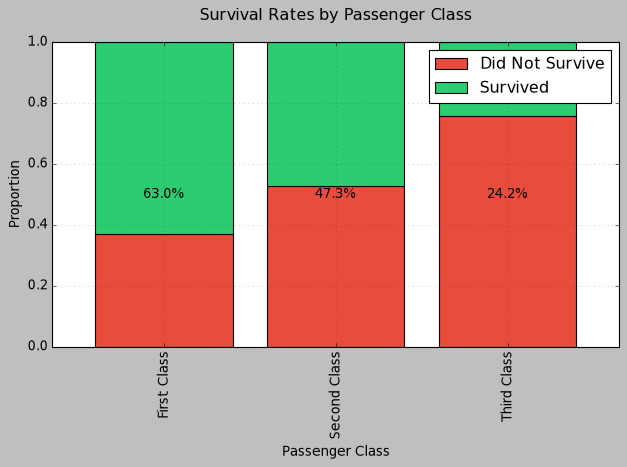

In [6]:
# Calculate survival rates by class
survival_by_class = pd.crosstab(
    df['pclass'],
    df['survived'],
    normalize='index'
)

plt.figure(figsize=(10, 6))

survival_by_class.plot(
    kind='bar',
    stacked=True,
    color=['#e74c3c', '#2ecc71'],  # Red for died, green for survived
    width=0.8
)

plt.title('Survival Rates by Passenger Class', pad=20)
plt.xlabel('Passenger Class')
plt.ylabel('Proportion')
plt.legend(['Did Not Survive', 'Survived'])

plt.xticks(
    range(3),
    ['First Class', 'Second Class', 'Third Class']
)

plt.grid(True, alpha=0.3)

# Add percentage labels
for i in range(len(survival_by_class)):
    plt.text(
        i,
        0.5,
        f"{survival_by_class.iloc[i, 1]:.1%}",
        ha='center',
        va='center'
    )

plt.tight_layout()
plt.show()

## 2. Sequential Colour Scales


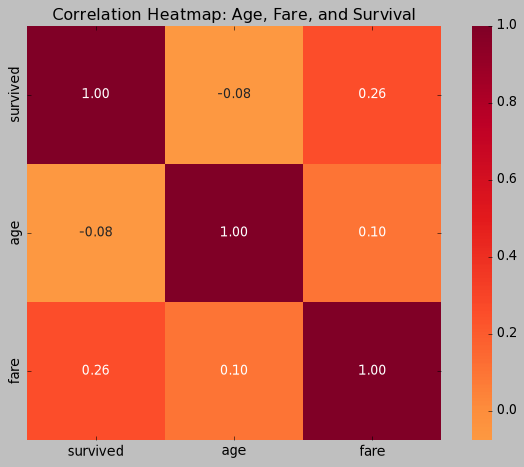

In [8]:
# Create correlation matrix
numeric_cols = ['survived', 'age', 'fare']
correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='YlOrRd',  # Yellow to Orange to Red sequential colormap
    center=0,
    fmt='.2f',
    square=True
)

plt.title('Correlation Heatmap: Age, Fare, and Survival')

plt.tight_layout()
plt.show()

## 3. Diverging Colour Scales

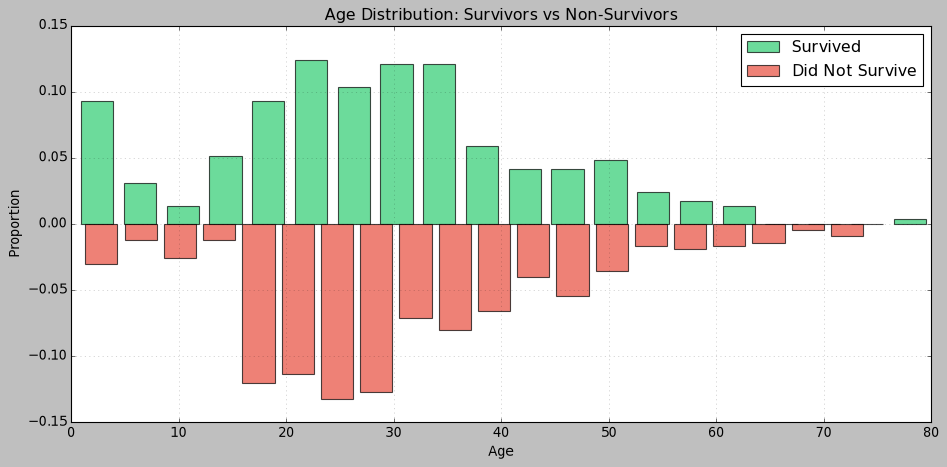

In [10]:
plt.figure(figsize=(12, 6))

# Calculate the difference in age distributions
survived_ages = df[df['survived'] == 1]['age'].value_counts(bins=20)
died_ages = df[df['survived'] == 0]['age'].value_counts(bins=20)

# Normalize the distributions
survived_ages = survived_ages / survived_ages.sum()
died_ages = -(died_ages / died_ages.sum())  # Negative for visualization

# Create diverging bar chart
plt.bar(
    survived_ages.index.mid,
    survived_ages.values,
    width=3,
    color='#2ecc71',
    alpha=0.7,
    label='Survived'
)

plt.bar(
    died_ages.index.mid,
    died_ages.values,
    width=3,
    color='#e74c3c',
    alpha=0.7,
    label='Did Not Survive'
)

plt.title('Age Distribution: Survivors vs Non-Survivors')
plt.xlabel('Age')
plt.ylabel('Proportion')

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Colour for Highlighting

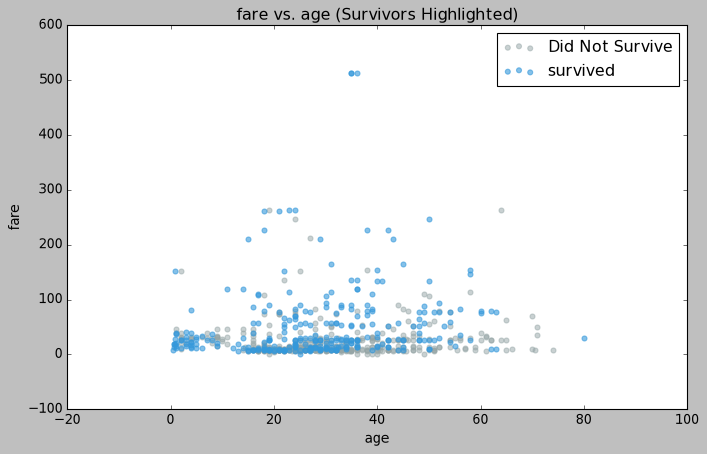

In [14]:
plt.figure(figsize=(10, 6))

# Plot non-survivors in grey
plt.scatter(df[df['survived'] == 0]['age'], 
           df[df['survived'] == 0]['fare'],
           color='#95a5a6', alpha=0.5, label='Did Not Survive')

# Highlight survivors in blue
plt.scatter(df[df['survived'] == 1]['age'], 
           df[df['survived'] == 1]['fare'],
           color='#3498db', alpha=0.6, label='survived')

plt.title('fare vs. age (Survivors Highlighted)')
plt.xlabel('age')
plt.ylabel('fare')
plt.legend()


## 5. Colour-Blind Friendly Visualisations


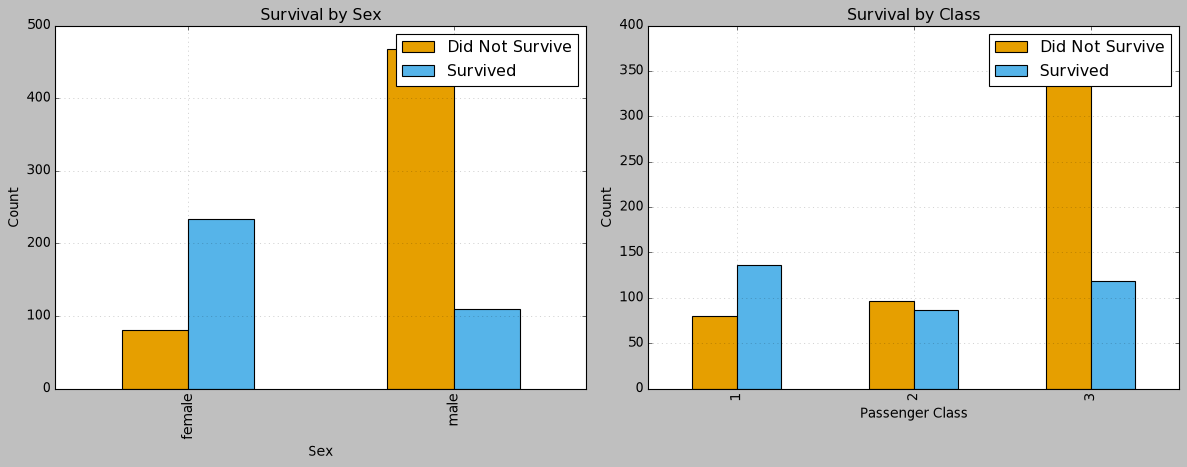

In [16]:
colors = ['#E69F00', '#56B4E9']  # Orange and light blue

# Create figure with multiple subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Survival by Sex
survival_by_sex = pd.crosstab(df['sex'], df['survived'])

survival_by_sex.plot(
    kind='bar',
    ax=ax1,
    color=colors
)

ax1.set_title('Survival by Sex')
ax1.set_xlabel('Sex')
ax1.set_ylabel('Count')
ax1.grid(True, alpha=0.3)

# Plot 2: Survival by Class
survival_by_class = pd.crosstab(df['pclass'], df['survived'])

survival_by_class.plot(
    kind='bar',
    ax=ax2,
    color=colors
)

ax2.set_title('Survival by Class')
ax2.set_xlabel('Passenger Class')
ax2.set_ylabel('Count')
ax2.grid(True, alpha=0.3)

# Add legends
ax1.legend(['Did Not Survive', 'Survived'])
ax2.legend(['Did Not Survive', 'Survived'])

plt.tight_layout()
plt.show()

## Exercises


**1: Qualitative Colour Scales**

**Objective:** Create a visualisation that shows the survival distribution across passenger classes and genders using appropriate qualitative colours.

**Task:** Create a grouped bar plot showing survival rates for males and females in each passenger class. Use colour-blind-friendly colours and ensure the visualisation is easily interpretable.

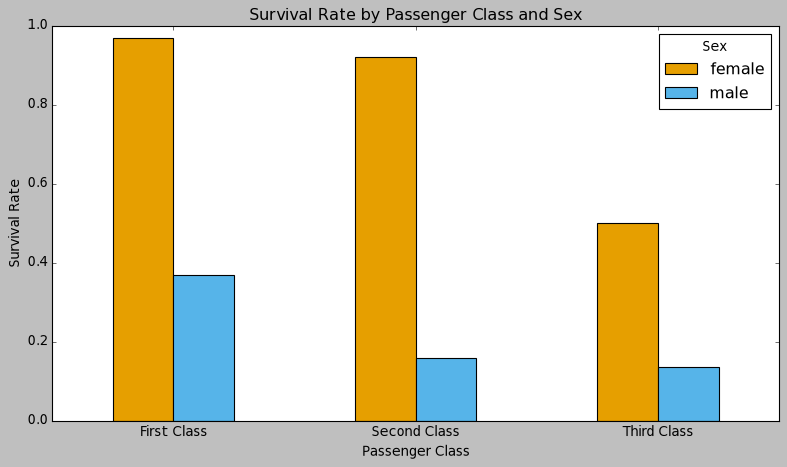

In [17]:
#Start your solution

# Exercise 1: Qualitative Colour Scales

# Calculate survival rate by passenger class and sex
survival_rates = (
    df.groupby(['pclass', 'sex'])['survived']
    .mean()
    .unstack()
)

# Colour-blind-friendly colours
colors = ['#E69F00', '#56B4E9']

# Create the grouped bar chart
survival_rates.plot(
    kind='bar',
    figsize=(10, 6),
    color=colors
)

# Add labels and title
plt.title('Survival Rate by Passenger Class and Sex')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

plt.xticks(
    ticks=[0, 1, 2],
    labels=['First Class', 'Second Class', 'Third Class'],
    rotation=0
)

plt.legend(title='Sex')

plt.tight_layout()

# Save the chart
plt.savefig(
    'survival_rate_by_class_and_sex.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


**2: Sequential Colour Scales**

**Objective:** Create a visualisation showing the relationship between ticket fare and survival probability using a sequential colour scale.

**Task:** Create a histogram of fare prices, with bins coloured according to the survival rate within each bin. Use a sequential colour scheme that goes from light to dark.


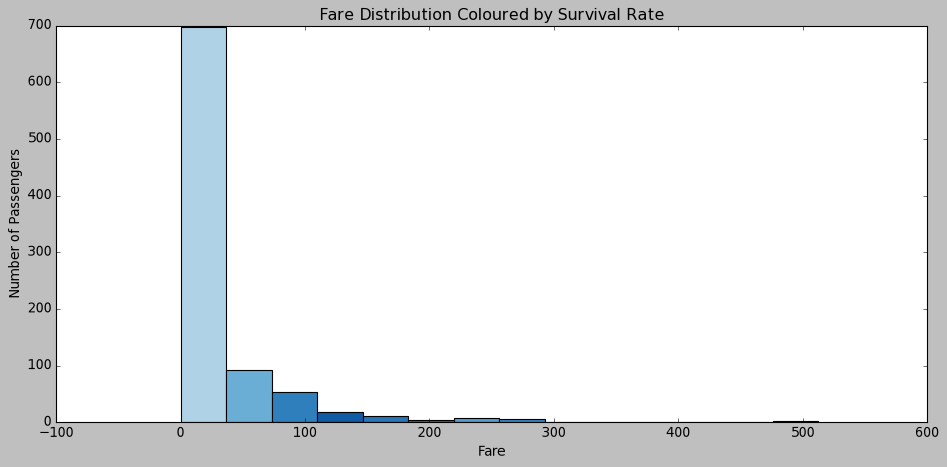

In [18]:
#Start your solution

# Exercise 2: Sequential Colour Scales

# Remove rows with missing fare values
fare_data = df[['fare', 'survived']].dropna()

# Create fare bins
bins = np.linspace(
    fare_data['fare'].min(),
    fare_data['fare'].max(),
    15
)

fare_data['fare_bin'] = pd.cut(
    fare_data['fare'],
    bins=bins,
    include_lowest=True
)

# Calculate passenger count and survival rate for each bin
fare_summary = fare_data.groupby(
    'fare_bin',
    observed=False
).agg(
    passenger_count=('fare', 'count'),
    survival_rate=('survived', 'mean')
)

# Get the centre of each fare bin
bin_centres = [
    interval.mid
    for interval in fare_summary.index
]

# Create sequential colours based on survival rate
colormap = plt.cm.Blues

colors = colormap(
    fare_summary['survival_rate'].fillna(0)
)

# Create the histogram-style bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    bin_centres,
    fare_summary['passenger_count'],
    width=bins[1] - bins[0],
    color=colors,
    edgecolor='black'
)

plt.title('Fare Distribution Coloured by Survival Rate')
plt.xlabel('Fare')
plt.ylabel('Number of Passengers')

plt.tight_layout()
plt.show()


**3: Diverging Colour Scales**

**Objective:** Create a visualisation that shows the age distribution difference between survivors and non-survivors using a diverging colour scale.

**Task:** Create a visualisation that shows whether certain age groups were over- or under-represented among survivors, compared to the overall age distribution.


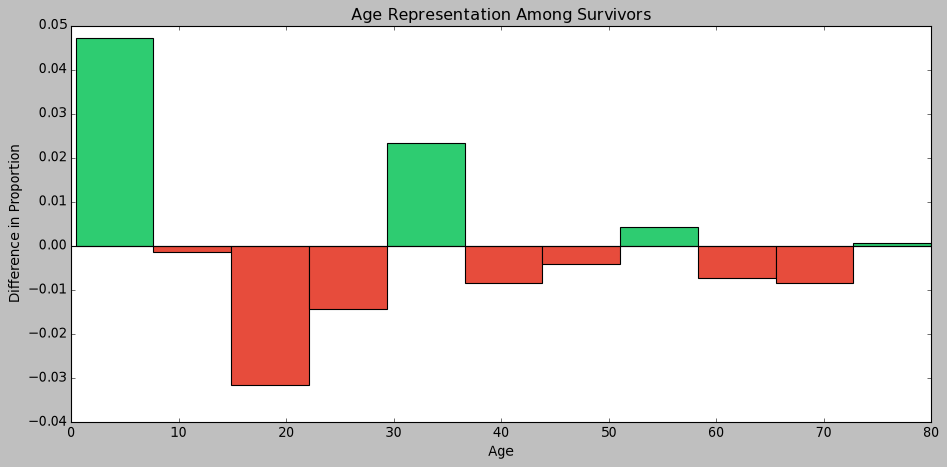

In [19]:
#Start your solution


# Exercise 3: Diverging Colour Scales

# Remove rows with missing age values
age_data = df[['age', 'survived']].dropna()

# Create age bins
bins = np.linspace(
    age_data['age'].min(),
    age_data['age'].max(),
    12
)

age_data['age_group'] = pd.cut(
    age_data['age'],
    bins=bins,
    include_lowest=True
)

# Overall age distribution
overall_distribution = (
    age_data['age_group']
    .value_counts(normalize=True)
    .sort_index()
)

# Age distribution among survivors
survivor_distribution = (
    age_data[age_data['survived'] == 1]['age_group']
    .value_counts(normalize=True)
    .sort_index()
)

# Difference between survivor distribution and overall distribution
difference = survivor_distribution - overall_distribution

# Get centre of each age group
age_centres = [
    interval.mid
    for interval in difference.index
]

# Use green for positive differences and red for negative differences
colors = []

for value in difference:
    if value >= 0:
        colors.append('#2ecc71')
    else:
        colors.append('#e74c3c')

# Create diverging bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    age_centres,
    difference,
    width=bins[1] - bins[0],
    color=colors,
    edgecolor='black'
)

plt.axhline(
    y=0,
    color='black'
)

plt.title('Age Representation Among Survivors')
plt.xlabel('Age')
plt.ylabel('Difference in Proportion')

plt.tight_layout()
plt.show()


**4: Highlighting with Colour**

**Objective:** Create a visualisation that effectively uses colour to highlight specific patterns in the data.

**Task:** Create a scatter plot of age vs. fare, using colour to highlight first-class passengers who survived while keeping other data points in neutral colours.


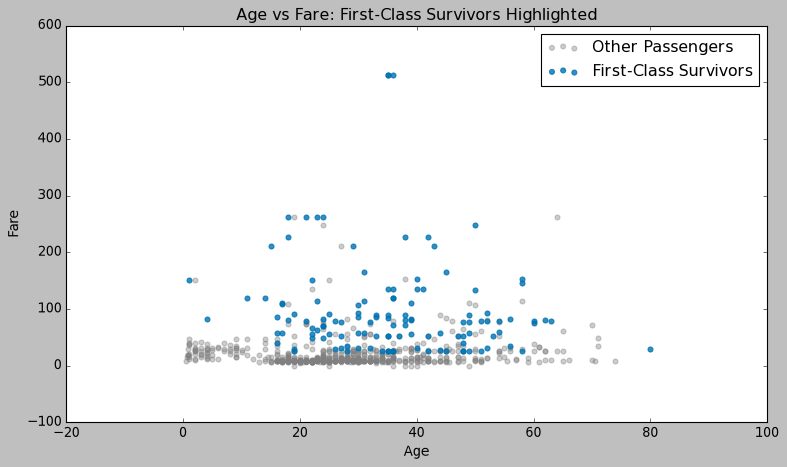

In [20]:
#Start your solution

# Exercise 4: Highlighting with Colour

# First-class passengers who survived
highlight = df[
    (df['pclass'] == 1) &
    (df['survived'] == 1)
]

# Everyone else
others = df[
    ~(
        (df['pclass'] == 1) &
        (df['survived'] == 1)
    )
]

plt.figure(figsize=(10, 6))

# Plot other passengers in grey
plt.scatter(
    others['age'],
    others['fare'],
    color='grey',
    alpha=0.4,
    label='Other Passengers'
)

# Highlight first-class survivors
plt.scatter(
    highlight['age'],
    highlight['fare'],
    color='#0072B2',
    alpha=0.8,
    label='First-Class Survivors'
)

plt.title('Age vs Fare: First-Class Survivors Highlighted')
plt.xlabel('Age')
plt.ylabel('Fare')

plt.legend()
plt.tight_layout()
plt.show()

**5: Colour-Blind-Friendly Dashboard**

**Objective:** Create a comprehensive dashboard using colour-blind-friendly colours that show multiple aspects of survival patterns.

**Task:** Create a multi-panel visualisation showing survival patterns across different variables, ensuring all colours used are colour-blind friendly.


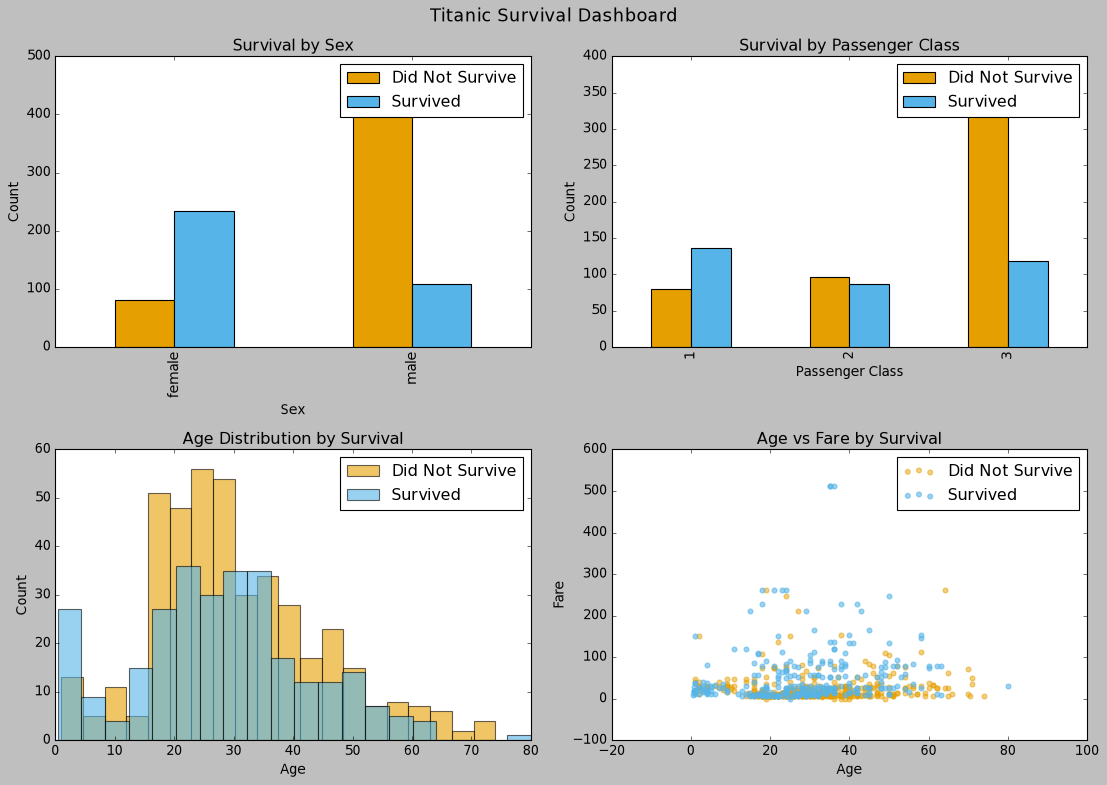

In [21]:
#Start your solution


# Exercise 5: Colour-Blind-Friendly Dashboard

# Colour-blind-friendly colours
colors = ['#E69F00', '#56B4E9']

# Create a 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Survival by sex
survival_by_sex = pd.crosstab(
    df['sex'],
    df['survived']
)

survival_by_sex.plot(
    kind='bar',
    ax=axes[0, 0],
    color=colors
)

axes[0, 0].set_title('Survival by Sex')
axes[0, 0].set_xlabel('Sex')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend(['Did Not Survive', 'Survived'])


# Plot 2: Survival by passenger class
survival_by_class = pd.crosstab(
    df['pclass'],
    df['survived']
)

survival_by_class.plot(
    kind='bar',
    ax=axes[0, 1],
    color=colors
)

axes[0, 1].set_title('Survival by Passenger Class')
axes[0, 1].set_xlabel('Passenger Class')
axes[0, 1].set_ylabel('Count')
axes[0, 1].legend(['Did Not Survive', 'Survived'])


# Plot 3: Age distribution by survival status
axes[1, 0].hist(
    df[df['survived'] == 0]['age'].dropna(),
    bins=20,
    alpha=0.6,
    color=colors[0],
    label='Did Not Survive'
)

axes[1, 0].hist(
    df[df['survived'] == 1]['age'].dropna(),
    bins=20,
    alpha=0.6,
    color=colors[1],
    label='Survived'
)

axes[1, 0].set_title('Age Distribution by Survival')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend()


# Plot 4: Fare vs age
axes[1, 1].scatter(
    df[df['survived'] == 0]['age'],
    df[df['survived'] == 0]['fare'],
    color=colors[0],
    alpha=0.5,
    label='Did Not Survive'
)

axes[1, 1].scatter(
    df[df['survived'] == 1]['age'],
    df[df['survived'] == 1]['fare'],
    color=colors[1],
    alpha=0.6,
    label='Survived'
)

axes[1, 1].set_title('Age vs Fare by Survival')
axes[1, 1].set_xlabel('Age')
axes[1, 1].set_ylabel('Fare')
axes[1, 1].legend()


# Add overall dashboard title
fig.suptitle(
    'Titanic Survival Dashboard',
    fontsize=16
)

plt.tight_layout()
plt.show()